In [38]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [39]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [40]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from tensorflow.keras.datasets import mnist

In [41]:
transform = transforms.Compose([
    transforms.ToTensor(),                      
    transforms.Normalize((0.1307,), (0.3081,))  
])

In [42]:
train_ds = datasets.MNIST('./data', train=True,  download=True, transform=transform)
test_ds  = datasets.MNIST('./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)

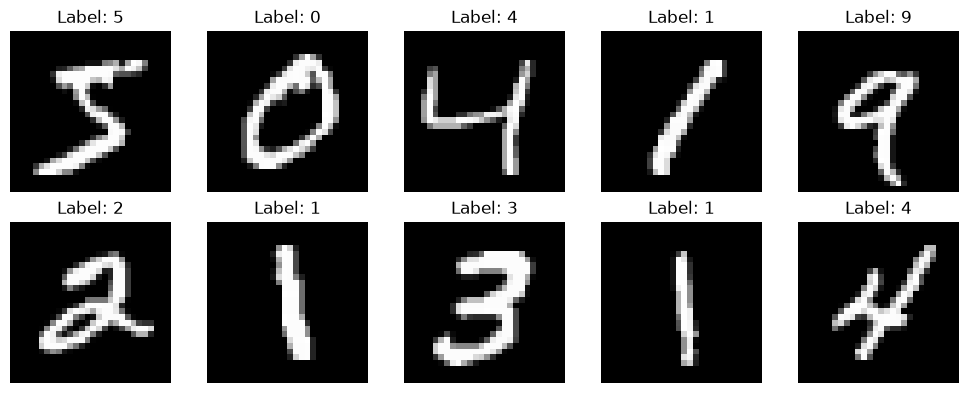

In [43]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    img, label = train_ds[i]      
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(f'Label: {label}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [44]:
class SmallNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2)
        self.fc1 = nn.Linear(64 * 3 * 3, 128)
        self.fc2 = nn.Linear(128, 10) 

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x))) 
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1) 
        x = self.fc2(F.relu(self.fc1(x)))
        return x

In [45]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SmallNN().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

In [46]:
EPOCHS = 10

In [47]:
model.train()
for epoch in range(EPOCHS):
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        optimizer.zero_grad()                    
        pred = model(data)
        loss = criterion(pred, target)           
        loss.backward()
        optimizer.step()

        if batch_idx % 200 == 0:
            print(f"epoch {epoch}, batch {batch_idx}, loss={loss.item():.4f}")

epoch 0, batch 0, loss=2.2981
epoch 0, batch 200, loss=0.0415
epoch 0, batch 400, loss=0.3231
epoch 0, batch 600, loss=0.0888
epoch 0, batch 800, loss=0.0631
epoch 1, batch 0, loss=0.0870
epoch 1, batch 200, loss=0.0458
epoch 1, batch 400, loss=0.0070
epoch 1, batch 600, loss=0.0089
epoch 1, batch 800, loss=0.0091
epoch 2, batch 0, loss=0.0246
epoch 2, batch 200, loss=0.0073
epoch 2, batch 400, loss=0.0983
epoch 2, batch 600, loss=0.0453
epoch 2, batch 800, loss=0.0017
epoch 3, batch 0, loss=0.0390
epoch 3, batch 200, loss=0.0123
epoch 3, batch 400, loss=0.0163
epoch 3, batch 600, loss=0.0107
epoch 3, batch 800, loss=0.0163
epoch 4, batch 0, loss=0.0085
epoch 4, batch 200, loss=0.0046
epoch 4, batch 400, loss=0.0051
epoch 4, batch 600, loss=0.0168
epoch 4, batch 800, loss=0.0782
epoch 5, batch 0, loss=0.0051
epoch 5, batch 200, loss=0.0019
epoch 5, batch 400, loss=0.0007
epoch 5, batch 600, loss=0.0258
epoch 5, batch 800, loss=0.0792
epoch 6, batch 0, loss=0.0414
epoch 6, batch 200, lo

In [48]:
torch.save(model.state_dict(), 'mnist_cnn.pth')

In [49]:
all_targets = []
all_preds = []

model.eval()
with torch.no_grad():
    for data, target in test_loader:
        data = data.to(device)
        target = target.to(device)

        logits = model(data)
        preds = logits.argmax(dim=1)

        all_targets.append(target.cpu().numpy())   
        all_preds.append(preds.cpu().numpy())      

y_true = np.concatenate(all_targets)
y_pred = np.concatenate(all_preds) 

In [50]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report, confusion_matrix

acc = accuracy_score(y_true, y_pred)
print("Accuracy:", acc)

prec_macro = precision_score(y_true, y_pred, average='macro')
rec_macro  = recall_score(y_true, y_pred, average='macro')

prec_weighted = precision_score(y_true, y_pred, average='weighted')
rec_weighted  = recall_score(y_true, y_pred, average='weighted')

print("Precision (macro):", prec_macro)
print("Recall (macro):", rec_macro)
print("Precision (weighted):", prec_weighted)
print("Recall (weighted):", rec_weighted)

print(classification_report(y_true, y_pred, digits=4))

cm = confusion_matrix(y_true, y_pred)
print(cm)

Accuracy: 0.9912
Precision (macro): 0.9911018840006445
Recall (macro): 0.9911816561080661
Precision (weighted): 0.9912353301534215
Recall (weighted): 0.9912
              precision    recall  f1-score   support

           0     0.9980    0.9949    0.9964       980
           1     0.9947    0.9974    0.9960      1135
           2     0.9942    0.9884    0.9913      1032
           3     0.9901    0.9941    0.9921      1010
           4     0.9869    0.9949    0.9909       982
           5     0.9812    0.9966    0.9889       892
           6     0.9937    0.9864    0.9900       958
           7     0.9855    0.9942    0.9898      1028
           8     0.9918    0.9908    0.9913       974
           9     0.9949    0.9742    0.9845      1009

    accuracy                         0.9912     10000
   macro avg     0.9911    0.9912    0.9911     10000
weighted avg     0.9912    0.9912    0.9912     10000

[[ 975    0    0    0    1    0    2    1    1    0]
 [   0 1132    0    0    0    1